**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

---

**中文对照（参考译文，不含解答）**

**生成式 AI 的使用**：本作业对生成式 AI 的使用采用与协作相同的规则。与其他协作者交流之后，每位学生仍须独立写出自己的解答，不能直接依赖交流中得到的输出；提交时应附上说明，如实记录协作的性质。使用生成式 AI 实质性地完成作业的大部分内容，不符合本作业的教学目的，也会违反[学术诚信准则](https://communitystandards.stanford.edu/policies-and-guidance/honor-code)。

In [1]:
# CS231n local environment setup (exercise code unchanged)
# [中文] CS231n 本地环境设置。
from pathlib import Path
import os
import sys

_candidates = [Path.cwd(), *Path.cwd().parents]
_workspace = next((p for p in _candidates if (p / "requirements-local.txt").is_file()
                   and (p / "assignment1" / "cs231n").is_dir()), None)
if _workspace is None:
    raise RuntimeError("Launch Jupyter from the CS231n workspace root.")
ASSIGNMENT_DIR = _workspace / "assignment1"
os.chdir(ASSIGNMENT_DIR)
if str(ASSIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ASSIGNMENT_DIR))
print("Python:", sys.executable)
print("Working directory:", Path.cwd())


Python: D:\cs231n\.venv\Scripts\python.exe
Working directory: D:\cs231n\assignment1


# Image features exercise
*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission. For more details see the [assignments page](http://vision.stanford.edu/teaching/cs231n/assignments.html) on the course website.*

We have seen that we can achieve reasonable performance on an image classification task by training a linear classifier on the pixels of the input image. In this exercise we will show that we can improve our classification performance by training linear classifiers not on raw pixels but on features that are computed from the raw pixels.

All of your work for this exercise will be done in this notebook.

---

**中文对照（参考译文，不含解答）**

# 图像特征练习

完成本 notebook，提交时保留运行输出及配套代码，课程链接见英文原文。此前直接用图片像素训练线性分类器；本节改用从像素中提取的特征，比较分类效果。此练习的工作都在本 notebook 中完成。

In [2]:
import random
import numpy as np
from cs231n.data_utils import load_CIFAR10
import matplotlib.pyplot as plt


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
# [中文] 设置图像的默认显示大小。
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading extenrnal modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
# [中文] 自动重载外部模块的相关说明见英文注释中的链接。
%load_ext autoreload
%autoreload 2

## Load data
Similar to previous exercises, we will load CIFAR-10 data from disk.

---

**中文对照（参考译文，不含解答）**

## 装入数据
与以往的练习类似,我们将从磁盘上装载CIFAR-10数据。

In [3]:
from cs231n.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Load the raw CIFAR-10 data
    # [中文] 加载原始 CIFAR-10 数据。
    cifar10_dir = 'cs231n/datasets/cifar-10-batches-py'

    # Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
    # [中文] 清除上次加载的变量，避免重复加载数据占用过多内存。
    try:
       del X_train, y_train
       del X_test, y_test
       print('Clear previously loaded data.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    # [中文] 截取一部分数据。
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

## Extract Features
For each image we will compute a Histogram of Oriented
Gradients (HOG) as well as a color histogram using the hue channel in HSV
color space. We form our final feature vector for each image by concatenating
the HOG and color histogram feature vectors.

Roughly speaking, HOG should capture the texture of the image while ignoring
color information, and the color histogram represents the color of the input
image while ignoring texture. As a result, we expect that using both together
ought to work better than using either alone. Verifying this assumption would
be a good thing to try for your own interest.

The `hog_feature` and `color_histogram_hsv` functions both operate on a single
image and return a feature vector for that image. The extract_features
function takes a set of images and a list of feature functions and evaluates
each feature function on each image, storing the results in a matrix where
each column is the concatenation of all feature vectors for a single image.

---

**中文对照（参考译文，不含解答）**

## 提取特征

对每张图片计算方向梯度直方图（HOG），以及 HSV 颜色空间中基于色相通道的颜色直方图，再将两者拼接为特征向量。HOG 主要描述纹理和轮廓，颜色直方图描述颜色分布，因此两者可能互补；也可以自行比较单独使用与组合使用的效果。hog_feature 和 color_histogram_hsv 分别对一张图提取特征；extract_features 对多张图片应用给定的特征函数，并将每张图片的拼接特征存入输出矩阵的一列。

In [4]:
from cs231n.features import *

# num_color_bins = 10 # Number of bins in the color histogram
num_color_bins = 25 # Number of bins in the color histogram
# [中文] 颜色直方图的区间数量。
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)]
X_train_feats = extract_features(X_train, feature_fns, verbose=True)
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Preprocessing: Subtract the mean feature
# [中文] 预处理：减去训练集的平均特征向量。
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat

# Preprocessing: Divide by standard deviation. This ensures that each feature
# has roughly the same scale.
# [中文] 预处理：每个特征除以它的标准差，使不同特征大致处于相同数值尺度。
std_feat = np.std(X_train_feats, axis=0, keepdims=True)
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat

# Preprocessing: Add a bias dimension
# [中文] 预处理：增加偏置维度。
X_train_feats = np.hstack([X_train_feats, np.ones((X_train_feats.shape[0], 1))])
X_val_feats = np.hstack([X_val_feats, np.ones((X_val_feats.shape[0], 1))])
X_test_feats = np.hstack([X_test_feats, np.ones((X_test_feats.shape[0], 1))])

Done extracting features for 1000 / 49000 images
Done extracting features for 2000 / 49000 images
Done extracting features for 3000 / 49000 images
Done extracting features for 4000 / 49000 images
Done extracting features for 5000 / 49000 images
Done extracting features for 6000 / 49000 images
Done extracting features for 7000 / 49000 images
Done extracting features for 8000 / 49000 images
Done extracting features for 9000 / 49000 images
Done extracting features for 10000 / 49000 images
Done extracting features for 11000 / 49000 images
Done extracting features for 12000 / 49000 images
Done extracting features for 13000 / 49000 images
Done extracting features for 14000 / 49000 images
Done extracting features for 15000 / 49000 images
Done extracting features for 16000 / 49000 images
Done extracting features for 17000 / 49000 images
Done extracting features for 18000 / 49000 images
Done extracting features for 19000 / 49000 images
Done extracting features for 20000 / 49000 images
Done extr

## Train Softmax classifier on features
Using the Softmax code developed earlier in the assignment, train Softmax classifiers on top of the features extracted above; this should achieve better results than training them directly on top of raw pixels.

---

**中文对照（参考译文，不含解答）**

## 在图像特征上训练 Softmax

复用前面完成的 Softmax 实现，用刚提取的图像特征训练分类器，并与直接使用原始像素的效果比较。

In [11]:
# Use the validation set to tune the learning rate and regularization strength
# [中文] 使用验证集选择学习率和正则化强度。

from cs231n.classifiers.linear_classifier import Softmax

learning_rates = [1e-3, 1e-2, 1e-1]
regularization_strengths = [1e-3, 1e-2, 1e-1]

results = {}
best_val = -1
best_softmax = None

################################################################################
# TODO:                                                                        #
# Use the validation set to set the learning rate and regularization strength. #
# This should be identical to the validation that you did for the Softmax; save#
# the best trained classifer in best_softmax. If you carefully tune the model, #
# you should be able to get accuracy of above 0.42 on the validation set.      #
################################################################################
# [中文] 待完成：用验证集选择学习率和正则化强度，方法与之前的 Softmax 调参相同。将验证表现最佳的已训练分类器存入 best_softmax。仔细调参后，验证准确率应能超过
# 0.42。
for lr in learning_rates:
    for rs in regularization_strengths:
        softmax = Softmax()
        loss_history = softmax.train(
            X_train_feats,
            y_train,
            learning_rate=lr,
            reg=rs,
        )
        
        y_train_pred = softmax.predict(X_train_feats)
        y_val_pred = softmax.predict(X_val_feats)
        train_accuracy = np.mean(y_train_pred==y_train)
        val_accuracy =np.mean(y_val_pred==y_val)
        
        results[(lr, rs)] = (train_accuracy, val_accuracy)

        if val_accuracy >= best_val:
            best_val = val_accuracy
            best_softmax = softmax
        
# Print out results.
# [中文] 打印结果。
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved: %f' % best_val)

lr 1.000000e-03 reg 1.000000e-03 train accuracy: 0.406286 val accuracy: 0.401000
lr 1.000000e-03 reg 1.000000e-02 train accuracy: 0.405408 val accuracy: 0.381000
lr 1.000000e-03 reg 1.000000e-01 train accuracy: 0.415714 val accuracy: 0.408000
lr 1.000000e-02 reg 1.000000e-03 train accuracy: 0.438980 val accuracy: 0.450000
lr 1.000000e-02 reg 1.000000e-02 train accuracy: 0.439490 val accuracy: 0.440000
lr 1.000000e-02 reg 1.000000e-01 train accuracy: 0.442265 val accuracy: 0.439000
lr 1.000000e-01 reg 1.000000e-03 train accuracy: 0.498510 val accuracy: 0.484000
lr 1.000000e-01 reg 1.000000e-02 train accuracy: 0.497612 val accuracy: 0.494000
lr 1.000000e-01 reg 1.000000e-01 train accuracy: 0.475082 val accuracy: 0.450000
best validation accuracy achieved: 0.494000


In [12]:
# Evaluate your trained Softmax on the test set: you should be able to get at least 0.42
# [中文] 在测试集上评估训练好的 Softmax；题目参考目标为准确率至少 0.42。
y_test_pred = best_softmax.predict(X_test_feats)
test_accuracy = np.mean(y_test == y_test_pred)
print(test_accuracy)

0.503


In [13]:
# Save best softmax model
# [中文] 保存验证表现最佳的 Softmax 模型。
best_softmax.save("best_softmax_features.npy")

best_softmax_features.npy saved.


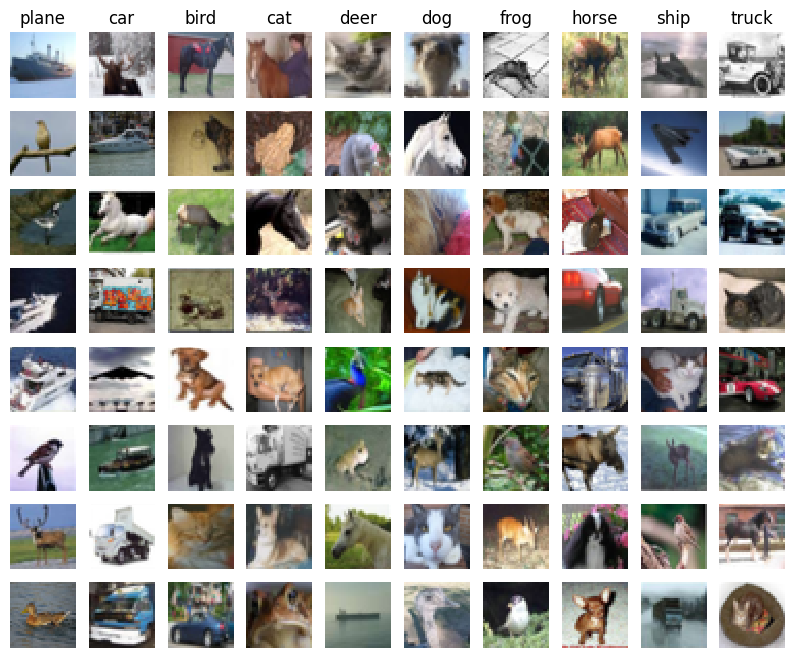

In [15]:
# An important way to gain intuition about how an algorithm works is to
# visualize the mistakes that it makes. In this visualization, we show examples
# of images that are misclassified by our current system. The first column
# shows images that our system labeled as "plane" but whose true label is
# something other than "plane".
# [中文] 可视化错误分类有助于理解算法。这里展示当前分类器误判的图片：第一列是被预测成 plane、但真实类别不是 plane 的图片。

examples_per_class = 8
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for cls, cls_name in enumerate(classes):
    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]
    idxs = np.random.choice(idxs, examples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(examples_per_class, len(classes), i * len(classes) + cls + 1)
        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls_name)
plt.show()

### Inline question 1:
Describe the misclassification results that you see. Do they make sense?


$\color{blue}{\textit Your Answer:}$





---

**中文对照（参考译文，不含解答）**

### 随堂问题 1

描述你观察到的错误分类结果。这些结果是否合理？

**你的回答：** 一些模型把船误认为飞机，把马误认为猫、狗等等，这些情况还是具有合理性的，因为不同类别的东西可能具有相同的颜色等特征，比如飞机和船都是白色的，且CIFAR-10分辨率较低，有些细节难以区分。

## Neural Network on image features
Earlier in this assigment we saw that training a two-layer neural network on raw pixels achieved better classification performance than linear classifiers on raw pixels. In this notebook we have seen that linear classifiers on image features outperform linear classifiers on raw pixels.

For completeness, we should also try training a neural network on image features. This approach should outperform all previous approaches: you should easily be able to achieve over 55% classification accuracy on the test set; our best model achieves about 60% classification accuracy.

---

**中文对照（参考译文，不含解答）**

## 在图像特征上训练神经网络

此前双层网络优于直接使用像素的线性分类器；本节又发现，图像特征能改善线性分类器。现在尝试在这些特征上训练神经网络，比较组合后的效果。正文给出的测试准确率参考目标为超过 55%，课程模型约为 60%。

In [16]:
# Preprocessing: Remove the bias dimension
# Make sure to run this cell only ONCE
# [中文] 预处理：移除偏置维度。此单元仅运行一次。
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [28]:
from cs231n.classifiers.fc_net import TwoLayerNet
from cs231n.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

net = TwoLayerNet(input_dim, hidden_dim, num_classes)
best_net = None
best_val = -1
################################################################################
# TODO: Train a two-layer neural network on image features. You may want to    #
# cross-validate various parameters as in previous sections. Store your best   #
# model in the best_net variable.                                              #
################################################################################
# [中文] 待完成：在图像特征上训练双层神经网络，像前面一样用交叉验证选择超参数，将最佳模型存入 best_net。
lr = 1e-1
regularization_strengths = [0.0, 1e-3, 1e-2]

for rs in regularization_strengths:
    net = TwoLayerNet(input_dim, hidden_dim, num_classes, reg=rs)
    
    solver = Solver(
        net,
        data,
        optim_config = {"learning_rate": lr},
        print_every=1000
    )

    solver.train()
    train_acc = solver.check_accuracy(X_train_feats, y_train)
    val_acc = solver.check_accuracy(X_val_feats, y_val)
    print(f"学习率: {lr}, 训练准确率: {train_acc:.4f}, "
          f"验证准确率: {val_acc:.4f}")
    if val_acc >= best_val:
        best_net = net
        best_val = val_acc
print("最佳验证准确率：", best_val)

(Iteration 1 / 4900) loss: 2.302547
(Epoch 0 / 10) train acc: 0.110000; val_acc: 0.112000
(Epoch 1 / 10) train acc: 0.532000; val_acc: 0.514000
(Epoch 2 / 10) train acc: 0.569000; val_acc: 0.517000
(Iteration 1001 / 4900) loss: 1.402972
(Epoch 3 / 10) train acc: 0.557000; val_acc: 0.542000
(Epoch 4 / 10) train acc: 0.613000; val_acc: 0.552000
(Iteration 2001 / 4900) loss: 1.126000
(Epoch 5 / 10) train acc: 0.660000; val_acc: 0.551000
(Epoch 6 / 10) train acc: 0.643000; val_acc: 0.566000
(Iteration 3001 / 4900) loss: 1.106424
(Epoch 7 / 10) train acc: 0.630000; val_acc: 0.597000
(Epoch 8 / 10) train acc: 0.655000; val_acc: 0.584000
(Iteration 4001 / 4900) loss: 0.975178
(Epoch 9 / 10) train acc: 0.680000; val_acc: 0.585000
(Epoch 10 / 10) train acc: 0.700000; val_acc: 0.597000
学习率: 0.1, 训练准确率: 0.6515, 验证准确率: 0.5970
(Iteration 1 / 4900) loss: 2.302610
(Epoch 0 / 10) train acc: 0.079000; val_acc: 0.113000
(Epoch 1 / 10) train acc: 0.479000; val_acc: 0.491000
(Epoch 2 / 10) train acc: 0.51

In [30]:
# Run your best neural net classifier on the test set. You should be able
# to get more than 58% accuracy. It is also possible to get >60% accuracy
# with careful tuning.
# [中文] 在测试集上评估选出的神经网络。题目参考目标为准确率超过 58%；仔细调参还可能超过 60%。

y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.59


In [31]:
# Save best model
# [中文] 保存验证表现最佳的模型。
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy saved.
